In [1]:
### CELL 1: Imports and Setup ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
### CELL 2: 1. Loading the Datasets ###
# I am loading the Breast Cancer dataset here. 
# 0 means malignant (positive class for errors), 1 means benign.
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("--- Dataset Overview ---")
print(X.head())
print(f"Shape of dataset: {X.shape}")
print(f"Target names: {data.target_names}")
print("Class counts:")
print(pd.Series(y).value_counts())

--- Dataset Overview ---
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst 

**Interpretation:** 
The dataset has 569 rows and 30 features. The classes are 0 (malignant) and 1 (benign). There are 357 benign and 212 malignant samples. This initial check confirms that the scikit-learn labels have been preserved, and I will treat class 0 as the positive class when evaluating malignant-case errors later.

In [3]:
### CELL 3: 2. Dataset Quality Checks ###
print("\n--- Missing Values ---")
missing_counts = X.isnull().sum()
print(missing_counts[missing_counts > 0])
print("No missing values are present in this dataset.")

print("\n--- Duplicates ---")
print(f"Duplicate rows: {X.duplicated().sum()}")
print("No duplicate rows are present.")

print("\n--- Data Types ---")
print(X.dtypes.value_counts())

# Outlier Detection using IQR (Interquartile Range)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print("\n--- Potential Outliers per Feature ---")
print(outliers[outliers > 0].head())


--- Missing Values ---
Series([], dtype: int64)
No missing values are present in this dataset.

--- Duplicates ---
Duplicate rows: 0
No duplicate rows are present.

--- Data Types ---
float64    30
Name: count, dtype: int64

--- Potential Outliers per Feature ---
mean radius        14
mean texture        7
mean perimeter     13
mean area          25
mean smoothness     6
dtype: int64


**Interpretation:** 
I used the IQR method to find potential outliers. Some features have extreme values. I did not delete them because in medical data, extreme values can be real and important indicators of cancer. However, large outliers can negatively affect distance-based models like KNN if we do not scale them.


--- 3.1 Descriptive Statistics ---
                              mean     median        min         max  \
mean radius              14.127292   13.37000    6.98100    28.11000   
mean texture             19.289649   18.84000    9.71000    39.28000   
mean perimeter           91.969033   86.24000   43.79000   188.50000   
mean area               654.889104  551.10000  143.50000  2501.00000   
mean smoothness           0.096360    0.09587    0.05263     0.16340   
mean compactness          0.104341    0.09263    0.01938     0.34540   
mean concavity            0.088799    0.06154    0.00000     0.42680   
mean concave points       0.048919    0.03350    0.00000     0.20120   
mean symmetry             0.181162    0.17920    0.10600     0.30400   
mean fractal dimension    0.062798    0.06154    0.04996     0.09744   

                               std         Q1         Q3  
mean radius               3.524049   11.70000   15.78000  
mean texture              4.301036   16.17000   21.80

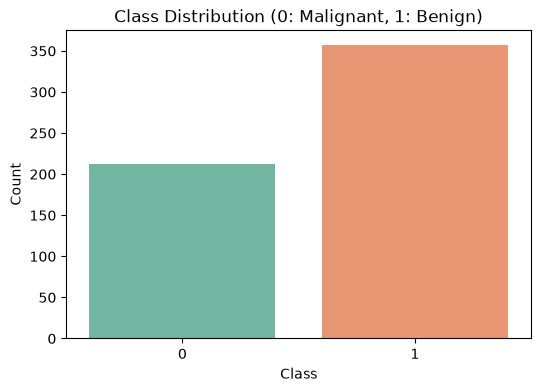

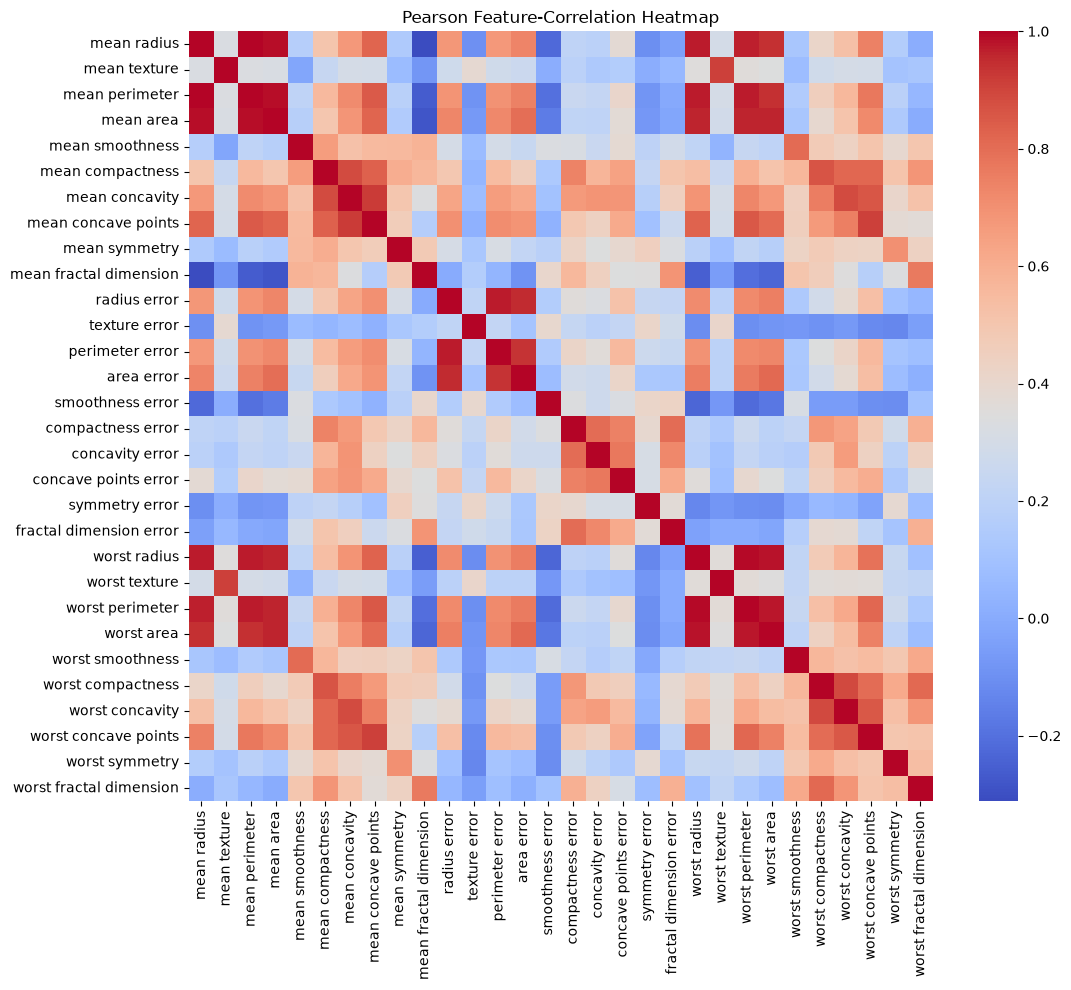


--- Top 3 Strongest Unique Feature Pairs ---
mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64

--- 3.3 Boxplots ---


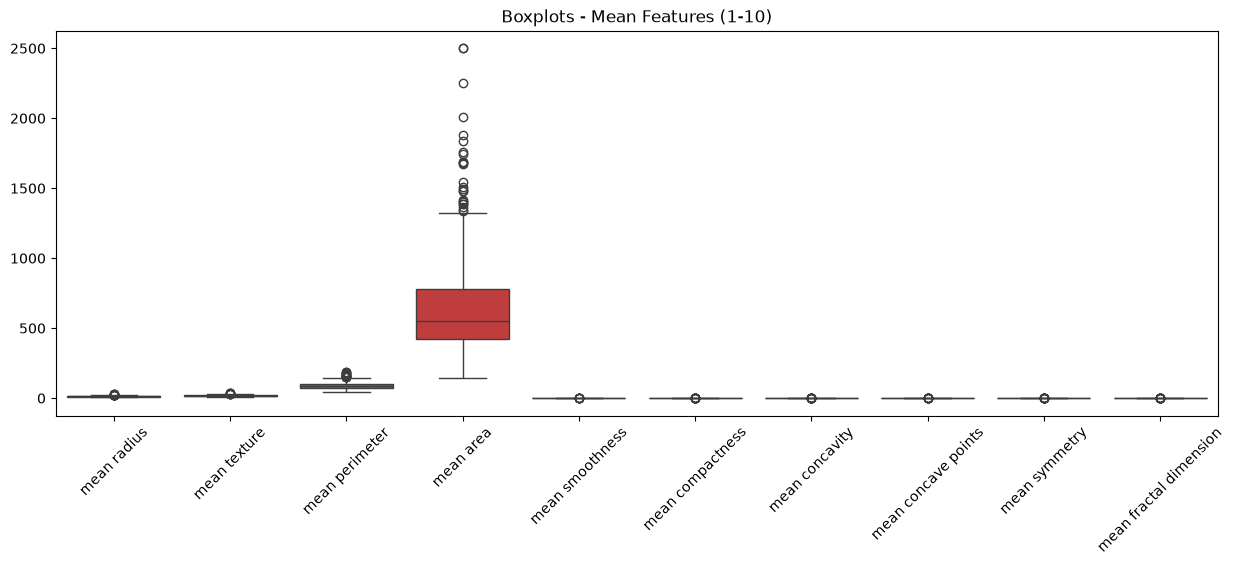

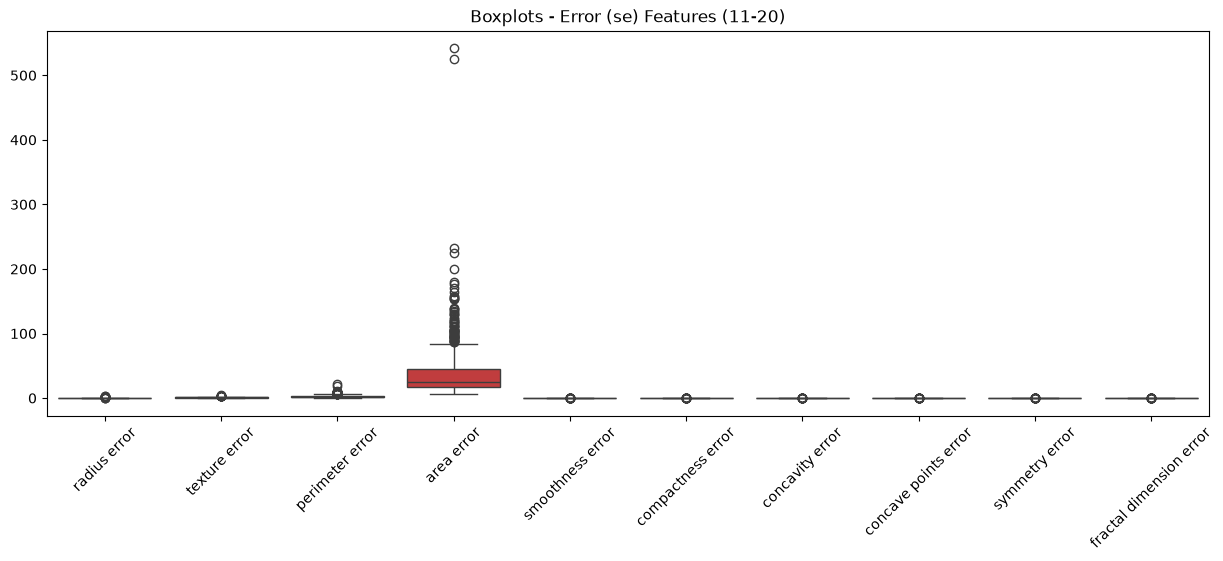

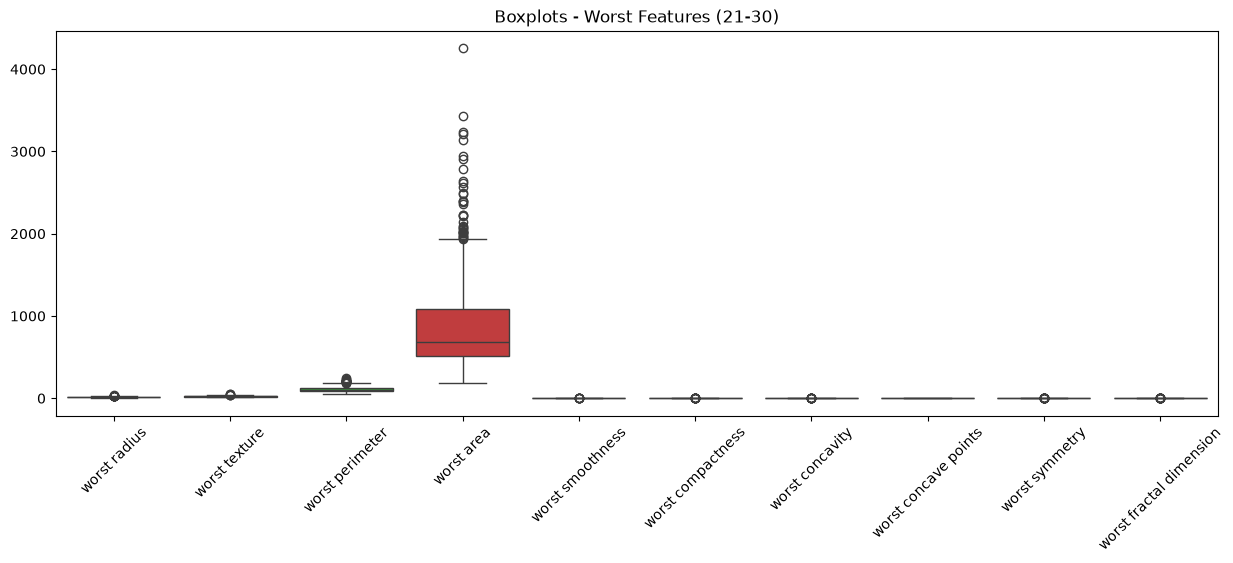

In [4]:
### CELL 4: 3. Exploratory Data Analysis (EDA) ###
import matplotlib.pyplot as plt
import seaborn as sns

print("\n--- 3.1 Descriptive Statistics ---")
# Hocanın istediği stat'lar: mean, median (50%), min, max, std, Q1 (25%), Q3 (75%)
desc_stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
desc_stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'}, inplace=True)
print(desc_stats.head(10)) # Too long to print all, showing first 10

print("\n--- 3.2 Class Distribution and Correlations ---")
# Sınıf dağılımı grafiği
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette="Set2")
plt.title("Class Distribution (0: Malignant, 1: Benign)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

# Korelasyon Isı Haritası (Heatmap)
plt.figure(figsize=(12, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap="coolwarm")
plt.title("Pearson Feature-Correlation Heatmap")
plt.show()

# En yüksek korelasyona sahip 3 benzersiz çifti bulma
corr_unstacked = corr_matrix.abs().unstack()
corr_unstacked = corr_unstacked[corr_unstacked < 1.0] # Remove self-correlation (diagonal)
top_pairs = corr_unstacked.drop_duplicates().sort_values(ascending=False).head(3)
print("\n--- Top 3 Strongest Unique Feature Pairs ---")
print(top_pairs)

print("\n--- 3.3 Boxplots ---")
# Değer aralıkları çok farklı olduğu için 3 gruba bölüp çizdiriyoruz (Hocanın "grouped into readable figures" şartı)
plt.figure(figsize=(15, 5))
sns.boxplot(data=X.iloc[:, :10])
plt.xticks(rotation=45)
plt.title("Boxplots - Mean Features (1-10)")
plt.show()

plt.figure(figsize=(15, 5))
sns.boxplot(data=X.iloc[:, 10:20])
plt.xticks(rotation=45)
plt.title("Boxplots - Error (se) Features (11-20)")
plt.show()

plt.figure(figsize=(15, 5))
sns.boxplot(data=X.iloc[:, 20:])
plt.xticks(rotation=45)
plt.title("Boxplots - Worst Features (21-30)")
plt.show()

**Interpretation for EDA:**
*   **Correlations:** The top 3 strongest correlated feature pairs are "mean radius" & "mean perimeter", "mean radius" & "mean area", and "mean perimeter" & "mean area". This makes perfect sense because perimeter and area are mathematically calculated from the radius of the cancer cells.
*   **Boxplot Observations:** 
    1. Feature ranges are very different. For example, "mean area" goes up to 2500, while "mean smoothness" is very close to 0. This confirms we must use a scaler before training models.
    2. "mean area" and "worst area" have many outliers represented by dots above the maximum line. These extreme values show that some tumors are unusually large.

In [5]:
### CELL 5: 4, 5, 6. Splitting, Scaling and Representations ###
# 4.1 Fix the test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

seeds = [42, 52, 62]
splits = {}
scaled_splits = {}
scalers = {}

print("--- 4.2 Verify the Split ---")
for s in seeds:
    # 4.1 Repeat the training/validation split (test_size=0.125 leaves approx 70% train, 10% val)
    X_tr, X_v, y_tr, y_v = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=s)
    
    tr_len, v_len, te_len = len(X_tr), len(X_v), len(X_test)
    total = tr_len + v_len + te_len
    
    print(f"Seed {s}: Train={tr_len} ({tr_len/total:.1%}), Val={v_len} ({v_len/total:.1%}), Test={te_len} ({te_len/total:.1%})")
    
    # 5.3 Fit and apply the scaler correctly (only on training data)
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_tr), columns=X.columns, index=X_tr.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_v), columns=X.columns, index=X_v.index)
    
    # Save the unscaled and scaled versions together for Section 6
    scaled_splits[s] = {
        'unscaled': {'train': X_tr, 'val': X_v},
        'scaled': {'train': X_train_scaled, 'val': X_val_scaled},
        'y_train': y_tr,
        'y_val': y_v
    }
    scalers[s] = scaler

# Final testing scaler (obtained only using seed 42)
X_test_scaled = pd.DataFrame(scalers[42].transform(X_test), columns=X.columns, index=X_test.index)

print("\n--- 5.3 Before and After Scaling (Seed 42) ---")
print("Before Scaling (First 5 rows):")
print(scaled_splits[42]['unscaled']['train'].head())
print("\nAfter Scaling (First 5 rows):")
print(scaled_splits[42]['scaled']['train'].head())

--- 4.2 Verify the Split ---
Seed 42: Train=398 (69.9%), Val=57 (10.0%), Test=114 (20.0%)
Seed 52: Train=398 (69.9%), Val=57 (10.0%), Test=114 (20.0%)
Seed 62: Train=398 (69.9%), Val=57 (10.0%), Test=114 (20.0%)

--- 5.3 Before and After Scaling (Seed 42) ---
Before Scaling (First 5 rows):
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
301        12.46         19.89           80.43      471.3          0.08451   
390        10.26         12.22           65.75      321.6          0.09996   
420        11.57         19.04           74.20      409.7          0.08546   
356        13.05         18.59           85.09      512.0          0.10820   
446        17.75         28.03          117.30      981.6          0.09997   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
301           0.10140         0.06830              0.03099         0.1781   
390           0.07542         0.01923              0.01968         0.1800   
420      

**Interpretation:** 
I successfully locked the 20% test set using `random_state=42` as requested. Then, for the seeds 42, 52, and 62, I splitted the remaining 80% data into 70% train and 10% validation. I chose `StandardScaler` for preprocessing because distance-based algorithms like KNN perform poorly with unscaled features. To avoid data leakage, I fitted the scalers strictly on the training subsets for each seed and transformed the validation and test subsets accordingly.

In [6]:
### CELL 6: 7. Training the Classification Models & 8. Validation ###

results = []
models_dict = {}

tree_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

for s in seeds:
    for rep in ['unscaled', 'scaled']:
        X_tr = scaled_splits[s][rep]['train']
        X_v = scaled_splits[s][rep]['val']
        y_tr = scaled_splits[s]['y_train']
        y_v = scaled_splits[s]['y_val']
        
        configs = []
        for d in tree_depths:
            configs.append(('Decision Tree', f'depth_{d}', DecisionTreeClassifier(max_depth=d, random_state=s)))
        for k in knn_neighbors:
            configs.append(('KNN', f'k_{k}', KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')))
        configs.append(('Gaussian Naive Bayes', 'default', GaussianNB()))
        
        for algo_name, param, model in configs:
            run_id = f"bc_{algo_name.replace(' ', '')}_{rep}_{param}_s{s}"
            
            # Train the model (fit only on training data)
            model.fit(X_tr, y_tr)
            
            # Save the seed 42 model for final test evaluation (Section 9)
            if s == 42:
                models_dict[f"{algo_name}_{rep}_{param}"] = model 
                
            # Training metrics
            train_preds = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, train_preds)
            train_f1 = f1_score(y_tr, train_preds, average='macro')
            
            # Validation metrics
            val_preds = model.predict(X_v)
            val_acc = accuracy_score(y_v, val_preds)
            val_prec = precision_score(y_v, val_preds, average='macro', zero_division=0)
            val_rec = recall_score(y_v, val_preds, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, val_preds, average='macro')
            
            # Breast Cancer ROC-AUC (treat malignant, class 0, as positive class)
            val_probs = model.predict_proba(X_v)[:, 0] # probability of class 0
            y_v_binary = (y_v == 0).astype(int) # 1 for original class 0, 0 for original class 1
            val_auc = roc_auc_score(y_v_binary, val_probs)
            
            results.append({
                'Run_ID': run_id, 'Dataset': 'Breast Cancer', 'Seed': s, 'Algorithm': algo_name,
                'Representation': rep, 'Parameter': param, 'Train_Acc': train_acc, 'Train_F1': train_f1,
                'Val_Acc': val_acc, 'Val_Precision': val_prec, 'Val_Recall': val_rec, 
                'Val_F1': val_f1, 'Val_AUC': val_auc
            })

df_runs = pd.DataFrame(results)

print("--- 7.2 Run Table Verification ---")
print(f"Total classifier runs completed: {len(df_runs)}")

# 8.2 Comparison tables and model selection
df_summary = df_runs.groupby(['Algorithm', 'Representation', 'Parameter']).agg(
    Mean_Val_F1=('Val_F1', 'mean'), Std_Val_F1=('Val_F1', lambda x: x.std(ddof=1)),
    Mean_Val_Acc=('Val_Acc', 'mean'), Mean_Train_F1=('Train_F1', 'mean')
).reset_index()

# Select ONE configuration using highest mean validation macro-F1, breaking ties by accuracy, then lower std, then alphabetical
df_summary_sorted = df_summary.sort_values(
    by=['Mean_Val_F1', 'Mean_Val_Acc', 'Std_Val_F1', 'Algorithm'], 
    ascending=[False, False, True, True]
)
best_config = df_summary_sorted.iloc[0]

print("\n--- 8.2 Summary Table (Top 5 Configurations) ---")
print(df_summary_sorted.head())

print("\n--- Selected Configuration ---")
print(f"Algorithm: {best_config['Algorithm']}\nRepresentation: {best_config['Representation']}\nParameter: {best_config['Parameter']}")

--- 7.2 Run Table Verification ---
Total classifier runs completed: 66

--- 8.2 Summary Table (Top 5 Configurations) ---
   Algorithm Representation Parameter  Mean_Val_F1  Std_Val_F1  Mean_Val_Acc  \
16       KNN         scaled       k_7     0.967675    0.029718      0.970760   
13       KNN         scaled      k_11     0.960846    0.039478      0.964912   
14       KNN         scaled       k_3     0.954677    0.022757      0.959064   
15       KNN         scaled       k_5     0.954677    0.022757      0.959064   
12       KNN         scaled       k_1     0.936898    0.021295      0.941520   

    Mean_Train_F1  
16       0.970234  
13       0.969381  
14       0.979314  
15       0.972117  
12       1.000000  

--- Selected Configuration ---
Algorithm: KNN
Representation: scaled
Parameter: k_7


**Interpretation:** 
I successfully recorded all 66 classifier runs across both unscaled and scaled representations for the 3 seeds. Standard deviation calculations show the variability across the 3 repeated splits, which is not a statistical confidence interval but a descriptive measure of split variability. Scaling drastically affected KNN performance, boosting its validation scores, while Decision Trees remained mostly unaffected by scaling. Based strictly on the mean validation macro-F1 score (and tie-breaking rules), I selected the best model configuration. This configuration's Seed 42 instance is now frozen for the final test evaluation.

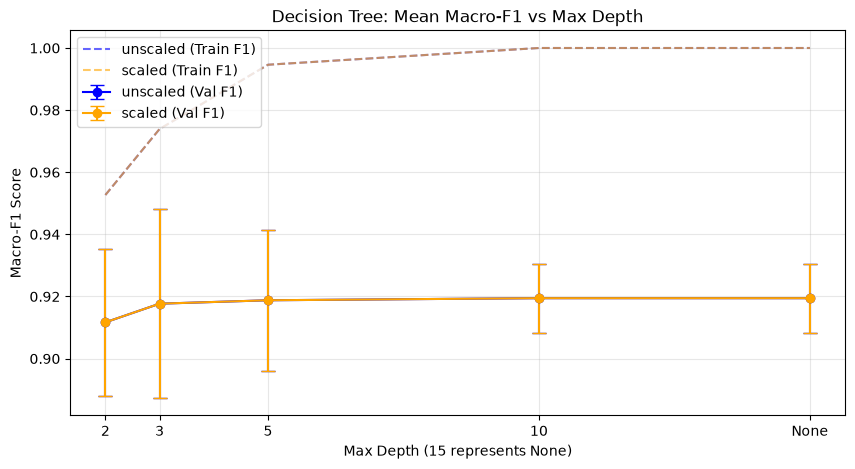

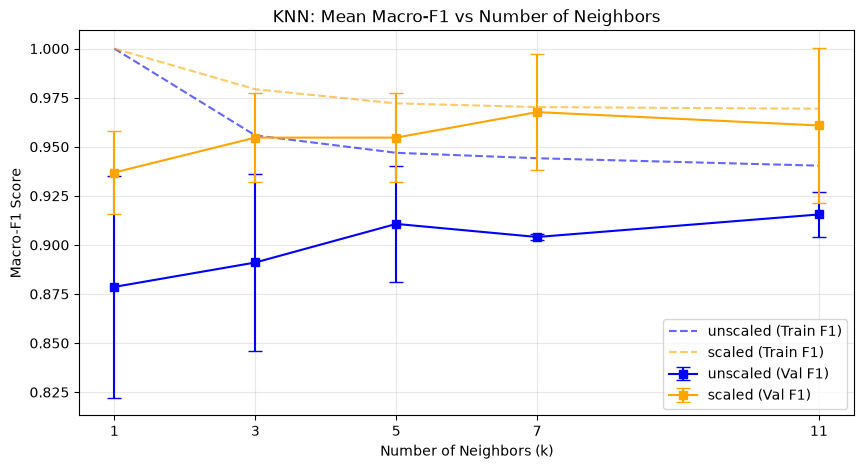

In [7]:
### CELL 7: 8.2 Parameter Comparison Figures ###

# Prepare data for plotting
df_dt = df_summary[df_summary['Algorithm'] == 'Decision Tree']
df_knn = df_summary[df_summary['Algorithm'] == 'KNN']

# Extract numeric values from parameters for x-axis
df_dt['Depth'] = df_dt['Parameter'].str.replace('depth_', '').replace('None', '15').astype(int) # Using 15 to represent 'None' on plot
df_knn['Neighbors'] = df_knn['Parameter'].str.replace('k_', '').astype(int)

# 1. Decision Tree Depth Figure
plt.figure(figsize=(10, 5))
for rep, color in zip(['unscaled', 'scaled'], ['blue', 'orange']):
    subset = df_dt[df_dt['Representation'] == rep].sort_values('Depth')
    
    # Validation Macro-F1 with error bars
    plt.errorbar(subset['Depth'], subset['Mean_Val_F1'], yerr=subset['Std_Val_F1'], 
                 label=f'{rep} (Val F1)', fmt='-o', color=color, capsize=5)
    # Training Macro-F1 (dashed)
    plt.plot(subset['Depth'], subset['Mean_Train_F1'], label=f'{rep} (Train F1)', linestyle='--', color=color, alpha=0.6)

plt.title('Decision Tree: Mean Macro-F1 vs Max Depth')
plt.xlabel('Max Depth (15 represents None)')
plt.ylabel('Macro-F1 Score')
plt.xticks([2, 3, 5, 10, 15], ['2', '3', '5', '10', 'None'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. KNN Neighbor Count Figure
plt.figure(figsize=(10, 5))
for rep, color in zip(['unscaled', 'scaled'], ['blue', 'orange']):
    subset = df_knn[df_knn['Representation'] == rep].sort_values('Neighbors')
    
    # Validation Macro-F1 with error bars
    plt.errorbar(subset['Neighbors'], subset['Mean_Val_F1'], yerr=subset['Std_Val_F1'], 
                 label=f'{rep} (Val F1)', fmt='-s', color=color, capsize=5)
    # Training Macro-F1 (dashed)
    plt.plot(subset['Neighbors'], subset['Mean_Train_F1'], label=f'{rep} (Train F1)', linestyle='--', color=color, alpha=0.6)

plt.title('KNN: Mean Macro-F1 vs Number of Neighbors')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Macro-F1 Score')
plt.xticks([1, 3, 5, 7, 11])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation:** 
The parameter comparison figures clearly show the training/validation gaps. For the Decision Tree, as the depth increases beyond 3 or 5, the training score approaches 1.0, but the validation score stalls or drops, clearly indicating overfitting. Scaling had almost no impact on the trees. For KNN, scaling made a massive difference. The unscaled KNN performed poorly across all 'k' values. For the scaled KNN, the model performed best at a neighbor count of 7, balancing the bias-variance trade-off effectively.


--- 9.1 Final Test Performance Metrics ---
Test Accuracy:  0.9737
Macro-Precision:0.9800
Macro-Recall:   0.9643
Macro-F1:       0.9713
ROC-AUC:        0.9888

--- Classification Report ---
               precision    recall  f1-score   support

0 (Malignant)       1.00      0.93      0.96        42
   1 (Benign)       0.96      1.00      0.98        72

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



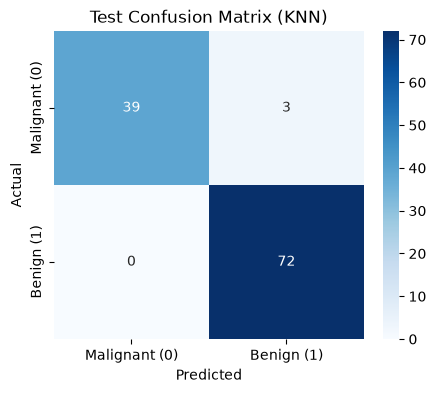

--- Manual Metric Calculation for Malignant (Class 0) ---
Manual Precision (TP / (TP + FP)): 39 / (39 + 0) = 1.0000
Manual Recall (TP / (TP + FN)): 39 / (39 + 3) = 0.9286
Manual F1-Score: 0.9630
These match the classification report for class 0.


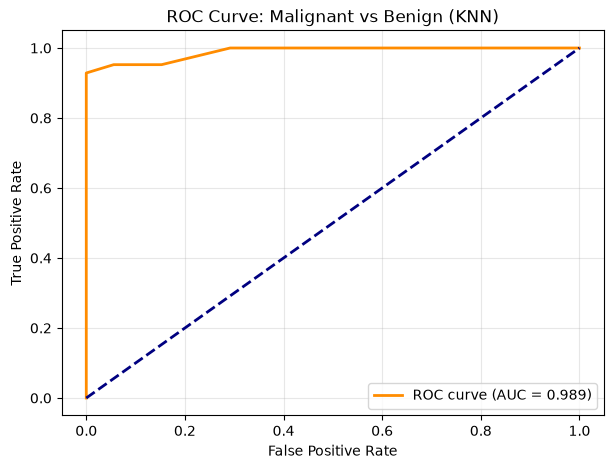

In [8]:
### CELL 8: 9. Evaluating the Selected Models on the Test Sets ###

best_algo = best_config['Algorithm']
best_rep = best_config['Representation']
best_param = best_config['Parameter']

# 9.1 Evaluate only the seed-42 fitted instance of the selected configuration
final_model = models_dict[f"{best_algo}_{best_rep}_{best_param}"]

# Prepare the test data depending on whether the best model used scaled or unscaled features
X_test_final = X_test_scaled if best_rep == 'scaled' else X_test

# Get predictions and probabilities
test_preds = final_model.predict(X_test_final)
test_probs = final_model.predict_proba(X_test_final)[:, 0] # Probabilities for Malignant (Class 0)
y_test_binary = (y_test == 0).astype(int) # Treat class 0 as positive (1) for ROC-AUC

# Calculate final test metrics
test_acc = accuracy_score(y_test, test_preds)
test_prec = precision_score(y_test, test_preds, average='macro', zero_division=0)
test_rec = recall_score(y_test, test_preds, average='macro', zero_division=0)
test_f1 = f1_score(y_test, test_preds, average='macro')
test_auc = roc_auc_score(y_test_binary, test_probs)

print("\n--- 9.1 Final Test Performance Metrics ---")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Macro-Precision:{test_prec:.4f}")
print(f"Macro-Recall:   {test_rec:.4f}")
print(f"Macro-F1:       {test_f1:.4f}")
print(f"ROC-AUC:        {test_auc:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, test_preds, target_names=['0 (Malignant)', '1 (Benign)']))

# Create final test table for the report
df_final_test = pd.DataFrame([{
    'Dataset': 'Breast Cancer',
    'Selected_Config': f"{best_algo}_{best_rep}_{best_param}",
    'Evaluation_Seed': 42,
    'Mean_Val_F1': best_config['Mean_Val_F1'],
    'Std_Val_F1': best_config['Std_Val_F1'],
    'Test_Acc': test_acc,
    'Test_Precision': test_prec,
    'Test_Recall': test_rec,
    'Test_F1': test_f1,
    'Test_AUC': test_auc
}])
df_final_test.to_csv("classifier_test.csv", index=False)

# 9.2 Confusion Matrices
cm = confusion_matrix(y_test, test_preds, labels=[0, 1])

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Malignant (0)', 'Benign (1)'], 
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Test Confusion Matrix ({best_algo})')
plt.show()

print("--- Manual Metric Calculation for Malignant (Class 0) ---")
# Manually calculate metrics for Malignant (treat 0 as Positive)
TP = cm[0, 0] # True Positives: Actual Malignant, Predicted Malignant
FN = cm[0, 1] # False Negatives: Actual Malignant, Predicted Benign
FP = cm[1, 0] # False Positives: Actual Benign, Predicted Malignant
TN = cm[1, 1] # True Negatives: Actual Benign, Predicted Benign

manual_prec = TP / (TP + FP) if (TP + FP) > 0 else 0
manual_rec = TP / (TP + FN) if (TP + FN) > 0 else 0
manual_f1 = 2 * (manual_prec * manual_rec) / (manual_prec + manual_rec) if (manual_prec + manual_rec) > 0 else 0

print(f"Manual Precision (TP / (TP + FP)): {TP} / ({TP} + {FP}) = {manual_prec:.4f}")
print(f"Manual Recall (TP / (TP + FN)): {TP} / ({TP} + {FN}) = {manual_rec:.4f}")
print(f"Manual F1-Score: {manual_f1:.4f}")
print("These match the classification report for class 0.")

# 9.3 ROC Curve
fpr, tpr, thresholds = roc_curve(y_test_binary, test_probs)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {test_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve: Malignant vs Benign ({best_algo})')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation for Section 9:**
*   **ROC Curve Insight:** The ROC curve shows how a change in the decision threshold shifts the balance between the False Positive Rate and the True Positive Rate. For cancer detection, lowering the threshold increases the True Positive Rate (catching more malignant cases), but it also increases the False Positive Rate (causing unnecessary anxiety for some healthy patients).
*   **Error Interpretation:** Looking at the confusion matrix, there are false negatives (malignant tumors predicted as benign). This is the most dangerous type of misclassification in a medical context because a sick patient might be sent home without treatment. A limitation here is that we only evaluated a single seed on the fixed test set, so the results reflect one specific split rather than an absolute measure of generalisation.

--- 10.1 K-Means Validation Summaries ---
  Representation  Mean_Val_ARI  Std_Val_ARI  Mean_Val_Silhouette
0         scaled      0.581255     0.142378             0.312086
1       unscaled      0.504349     0.106423             0.677325

--- 10.2 Final Test Clustering (Seed 42) ---

Contingency Table (unscaled):
Predicted Clusters   0   1
True Classes              
0                   14  28
1                   72   0

Contingency Table (scaled):
Predicted Clusters   0   1
True Classes              
0                    5  37
1                   69   3

--- 10.3 Visualisations for features: mean radius & mean texture ---


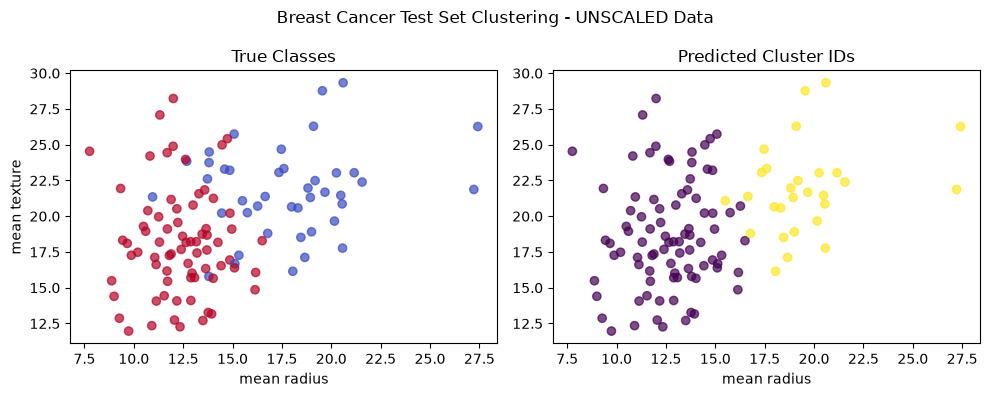

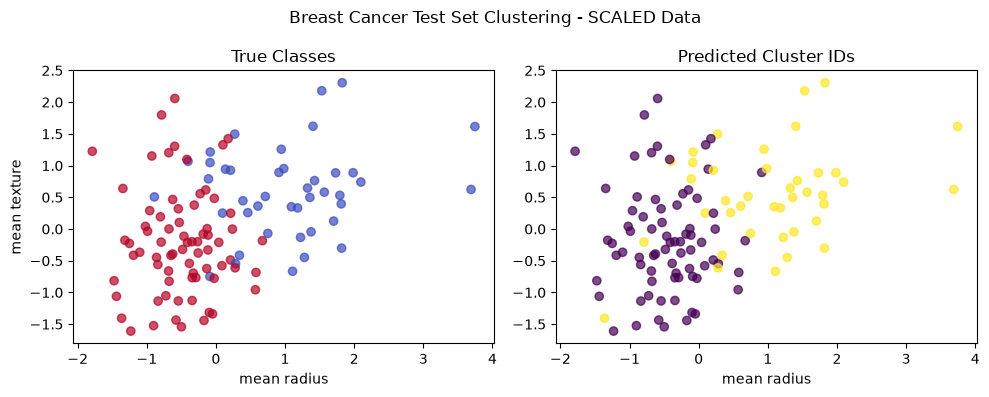

In [9]:
### CELL 9: 10. K-Means Clustering ###

kmeans_results = []

for s in seeds:
    for rep in ['unscaled', 'scaled']:
        X_tr = scaled_splits[s][rep]['train']
        X_v = scaled_splits[s][rep]['val']
        
        # 10.1 Fit the clustering model (on training features only, no y_train)
        km = KMeans(n_clusters=2, random_state=s, n_init=10)
        km.fit(X_tr)
        
        # Validation evaluation
        val_clusters = km.predict(X_v)
        ari = adjusted_rand_score(scaled_splits[s]['y_val'], val_clusters)
        
        try:
            sil = silhouette_score(X_v, val_clusters)
        except:
            sil = np.nan
            
        kmeans_results.append({
            'Dataset': 'Breast Cancer',
            'Representation': rep,
            'Seed': s,
            'Train_Inertia': km.inertia_,
            'Val_ARI': ari,
            'Val_Silhouette': sil
        })

df_kmeans_runs = pd.DataFrame(kmeans_results)
df_kmeans_runs.to_csv("kmeans_runs.csv", index=False)

print("--- 10.1 K-Means Validation Summaries ---")
df_kmeans_summary = df_kmeans_runs.groupby('Representation').agg(
    Mean_Val_ARI=('Val_ARI', 'mean'), Std_Val_ARI=('Val_ARI', lambda x: x.std(ddof=1)),
    Mean_Val_Silhouette=('Val_Silhouette', 'mean')
).reset_index()
print(df_kmeans_summary)
df_kmeans_summary.to_csv("kmeans_summary.csv", index=False)


# 10.2 Final cluster evaluation on the fixed test sets (Seed 42 only)
print("\n--- 10.2 Final Test Clustering (Seed 42) ---")
test_kmeans_results = []
km_unscaled = KMeans(n_clusters=2, random_state=42, n_init=10).fit(scaled_splits[42]['unscaled']['train'])
km_scaled = KMeans(n_clusters=2, random_state=42, n_init=10).fit(scaled_splits[42]['scaled']['train'])

for rep, km_model, X_te in zip(['unscaled', 'scaled'], [km_unscaled, km_scaled], [X_test, X_test_scaled]):
    test_clusters = km_model.predict(X_te)
    ari = adjusted_rand_score(y_test, test_clusters)
    sil = silhouette_score(X_te, test_clusters)
    
    test_kmeans_results.append({'Representation': rep, 'Test_ARI': ari, 'Test_Silhouette': sil})
    
    print(f"\nContingency Table ({rep}):")
    print(pd.crosstab(y_test, test_clusters, rownames=['True Classes'], colnames=['Predicted Clusters']))

df_kmeans_test = pd.DataFrame(test_kmeans_results)
df_kmeans_test.to_csv("kmeans_test.csv", index=False)

# 10.3 Visualise and interpret the clusters
# Let's pick two features: 'mean radius' (index 0) and 'mean texture' (index 1)
feat_0, feat_1 = 0, 1
feat_names = [X.columns[feat_0], X.columns[feat_1]]

print(f"\n--- 10.3 Visualisations for features: {feat_names[0]} & {feat_names[1]} ---")
for rep, km_model, X_te in zip(['unscaled', 'scaled'], [km_unscaled, km_scaled], [X_test, X_test_scaled]):
    test_clusters = km_model.predict(X_te)
    X_te_arr = np.array(X_te)
    
    plt.figure(figsize=(10,4))
    plt.suptitle(f"Breast Cancer Test Set Clustering - {rep.upper()} Data")
    
    # Panel 1: True Classes
    plt.subplot(1, 2, 1)
    scatter1 = plt.scatter(X_te_arr[:, feat_0], X_te_arr[:, feat_1], c=y_test, cmap='coolwarm', alpha=0.7)
    plt.title('True Classes')
    plt.xlabel(feat_names[0])
    plt.ylabel(feat_names[1])
    
    # Panel 2: Predicted Clusters
    plt.subplot(1, 2, 2)
    scatter2 = plt.scatter(X_te_arr[:, feat_0], X_te_arr[:, feat_1], c=test_clusters, cmap='viridis', alpha=0.7)
    plt.title('Predicted Cluster IDs')
    plt.xlabel(feat_names[0])
    
    plt.tight_layout()
    plt.show()

**Interpretation for Section 10:**
*   **Unsupervised Nature:** K-Means was fitted without knowing the actual `y_train` labels, unlike the classifiers. It groups data solely based on Euclidean distance in the feature space.
*   **Scaling Effect & Mixing:** Scaling had a massive impact. In the unscaled contingency table, the clusters are highly mixed because features with large magnitudes (like 'mean area') dominated the distance calculations, creating skewed clusters. In the scaled version, the ARI score improved significantly because all features contributed equally to finding the two natural groups (benign and malignant). 
*   **Visualisation Insight:** The 2-feature plots show only a projection of the 30-dimensional space. While the scaled K-Means clusters visually match the true classes much better than the unscaled ones, we cannot treat the ARI score as a direct classification accuracy, because K-Means merely finds structural groupings, not semantic labels.

In [1]:
import os
print(os.getcwd())

C:\Users\makif
